# 02 — EDA da 1ª experiência

**Pergunta:** o que diferencia, sem ajuste, quem volta em 7 dias de quem não volta?

- Fonte: `etl/primeira_experiencia.py`, uma linha por usuário, com as definições aceitas (BDR-001 a 010).
- O **conteúdo** (tema, recusa, modelo, idioma, tamanho da resposta) vem da **1ª conversa**. O **volume**
  (conversas, respostas) vem da **1ª sessão** inteira.
- Todo número é **bruto**: sem ajuste por perfil. O notebook 04 separa efeito de seleção. IC 95% de Wilson.
- Cada gráfico existe porque sustenta uma conclusão. A conclusão vem logo abaixo dele.

In [1]:
from estilo import AZUL, BRUTA, FUNDO, TINTA_2, TINTA_MUDA, VOLUME, aplicar  # põe etl/ no path

import warnings

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from estatistica import wilson
from primeira_experiencia import TEMAS, construir_primeira_experiencia

aplicar()
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", message="The inplace keyword")  # aviso interno do DuckDB → pandas

con = duckdb.connect()
con.execute("SET memory_limit = '3GB'")
pe = construir_primeira_experiencia(con, BRUTA, str(TEMAS), volume_diario=VOLUME)
el = pe[pe.elegivel].copy()
GERAL = el.voltou_7d.mean()
FONTE_BASE = "Fonte: WildChat-1M, Brasil, 04/2023–04/2024 · etl/primeira_experiencia.py"
FONTE = FONTE_BASE + " · IC 95% de Wilson"
print(f"usuários elegíveis: {len(el)} | retorno em 7 dias: {GERAL:.1%} | sem tema: {int(el.tema.isna().sum())}")

usuários elegíveis: 2219 | retorno em 7 dias: 28.6% | sem tema: 0


In [2]:
ROTULOS = {
    "tarefa_conhecimento": "Tarefa: conhecimento, estudo, trabalho",
    "saudacao_teste": "Saudação ou teste",
    "programacao_tecnologia": "Programação e tecnologia",
    "criativo_entretenimento": "Criativo e entretenimento",
    "traducao_reescrita": "Tradução e reescrita",
    "conselho_pessoal": "Conselho pessoal",
    "outro": "Outro",
    "portugues": "Português", "ingles": "Inglês",
    "desktop": "Desktop", "mobile": "Celular",
    "Federal District": "Distrito Federal",
    "madrugada": "Madrugada (0–5h)", "manha": "Manhã (6–11h)", "tarde": "Tarde (12–17h)", "noite": "Noite (18–23h)",
}


def por_nivel(df: pd.DataFrame, col: str, ordem: list | None = None) -> pd.DataFrame:
    """Taxa de retorno por nível, com IC de Wilson. Sem `ordem`: ordena da maior para a menor taxa."""
    g = df.groupby(col, observed=True).voltou_7d.agg(n="size", k="sum")
    g["taxa"] = g.k / g.n
    g[["lo", "hi"]] = [wilson(int(k), int(n)) for k, n in zip(g.k, g.n, strict=True)]
    return g.reindex(ordem) if ordem is not None else g.sort_values("taxa", ascending=False)


def pontos(ax: plt.Axes, g: pd.DataFrame, titulo: str, rotulos: dict | None = None) -> None:
    """Ponto = taxa; traço = IC 95%; linha tracejada = média geral."""
    y = list(range(len(g)))
    ax.hlines(y, g.lo * 100, g.hi * 100, color=AZUL, lw=2)
    ax.plot(g.taxa * 100, y, "o", color=AZUL, ms=8, mec=FUNDO, mew=2)
    ax.axvline(GERAL * 100, color=TINTA_MUDA, ls="--", lw=1)
    nomes = [f"{(rotulos or ROTULOS).get(str(i), str(i))}  (n={n})" for i, n in zip(g.index, g.n, strict=True)]
    ax.set_yticks(y, nomes)
    ax.set_ylim(len(g) - 0.5, -0.5)
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo, fontsize=10)


def painel(blocos: list[tuple[str, pd.DataFrame, dict | None]], titulo: str, xmax: int = 65) -> None:
    """Small multiples empilhados, com o mesmo eixo x (taxa de retorno em 7 dias, %)."""
    alturas = [len(g) for _, g, _ in blocos]
    fig, axes = plt.subplots(len(blocos), 1, figsize=(9, 0.42 * sum(alturas) + 1.6 * len(blocos)),
                             gridspec_kw={"height_ratios": alturas}, sharex=True)
    axes = [axes] if len(blocos) == 1 else axes
    for ax, (t, g, r) in zip(axes, blocos, strict=True):
        pontos(ax, g, t, r)
    axes[-1].set_xlim(0, xmax)
    axes[-1].set_xlabel("retorno em 7 dias (%) · linha tracejada = média geral")
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.text(0.01, 0.005, FONTE, fontsize=8, color=TINTA_MUDA)
    fig.tight_layout(rect=(0, 0.02, 1, 1))
    plt.show()

## 1. Quando a pessoa volta?

observáveis por 30 dias: 2043
até 6 h      15.7
6–24 h        6.3
1–2 dias      2.3
2–7 dias      4.3
7–30 dias     1.9
voltaram em 30 dias: 30.6% | desses, em até 7 dias: 93.8%
dos que voltam em 7 dias, em até 6 h: 54.8%


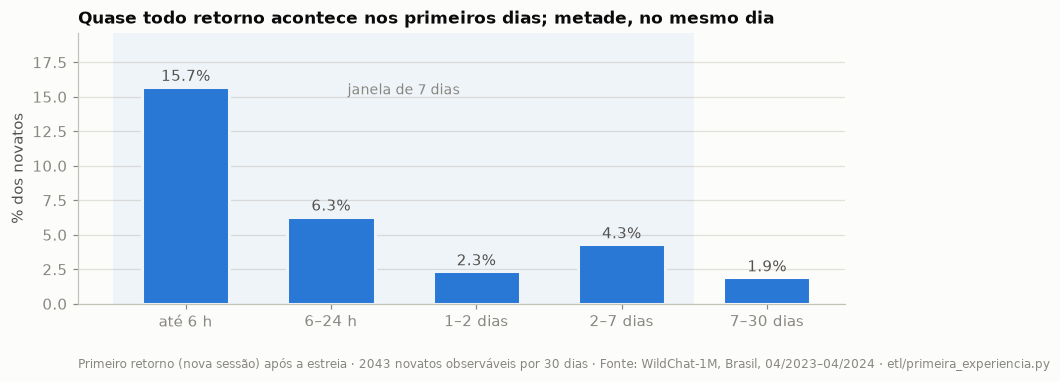

In [3]:
fim_base = con.execute("SELECT max(fim_utc) AS fim FROM conversas").df().fim[0]  # fetchone() exigiria pytz
seg = con.execute("""
    SELECT usuario_id, min(inicio_utc) FILTER (sessao_seq = 2) AS t2 FROM sessoes GROUP BY 1
""").df()
obs30 = el[el.primeira_inicio_utc + pd.Timedelta(days=30) <= fim_base].merge(seg, on="usuario_id")
horas = (obs30.t2 - obs30.primeira_inicio_utc).dt.total_seconds() / 3600
faixas = pd.cut(horas, [0, 6, 24, 48, 168, 720], labels=["até 6 h", "6–24 h", "1–2 dias", "2–7 dias", "7–30 dias"])
dist = faixas.value_counts(sort=False) / len(obs30)
print(f"observáveis por 30 dias: {len(obs30)}")
print((dist * 100).round(1).to_string())
print(f"voltaram em 30 dias: {dist.sum():.1%} | desses, em até 7 dias: {dist.iloc[:4].sum() / dist.sum():.1%}")
print(f"dos que voltam em 7 dias, em até 6 h: {dist.iloc[0] / dist.iloc[:4].sum():.1%}")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(len(dist)), dist * 100, color=AZUL, width=0.6, edgecolor=FUNDO, linewidth=2)
for i, v in enumerate(dist * 100):
    ax.annotate(f"{v:.1f}%", (i, v), xytext=(0, 4), textcoords="offset points", ha="center", color=TINTA_2)
ax.axvspan(-0.5, 3.5, color=AZUL, alpha=0.06, lw=0)
ax.annotate("janela de 7 dias", (1.5, ax.get_ylim()[1] * 0.92), ha="center", color=TINTA_MUDA, fontsize=9)
ax.set_xticks(range(len(dist)), dist.index)
ax.set_ylabel("% dos novatos")
ax.set_ylim(0, dist.max() * 100 * 1.25)
ax.set_title("Quase todo retorno acontece nos primeiros dias; metade, no mesmo dia")
ax.annotate(f"Primeiro retorno (nova sessão) após a estreia · {len(obs30)} novatos observáveis por 30 dias · " + FONTE_BASE,
            xy=(0, -0.2), xycoords="axes fraction", fontsize=8, color=TINTA_MUDA, va="top")
plt.show()

**Conclusão:**
- **94% dos retornos em 30 dias acontecem em até 7 dias.** A janela de 7 dias do enunciado perde pouco.
- **Mais da metade dos retornos em 7 dias acontece em até 6 horas.** "Voltar", nesta base, é quase sempre
  retomar no mesmo dia, depois de uma pausa de mais de 30 minutos. Isso explica por que o gap da sessão
  (BDR-002) mexe tanto na taxa: 15 minutos dariam +5,4 p.p.
- Para o cliente: o retorno se decide **na estreia e nas horas seguintes**, não ao longo da semana.

## 2. O que a pessoa foi fazer e o que encontrou

limites dos quartis da 1ª resposta (caracteres): [119.0, 947.0, 2060.0]


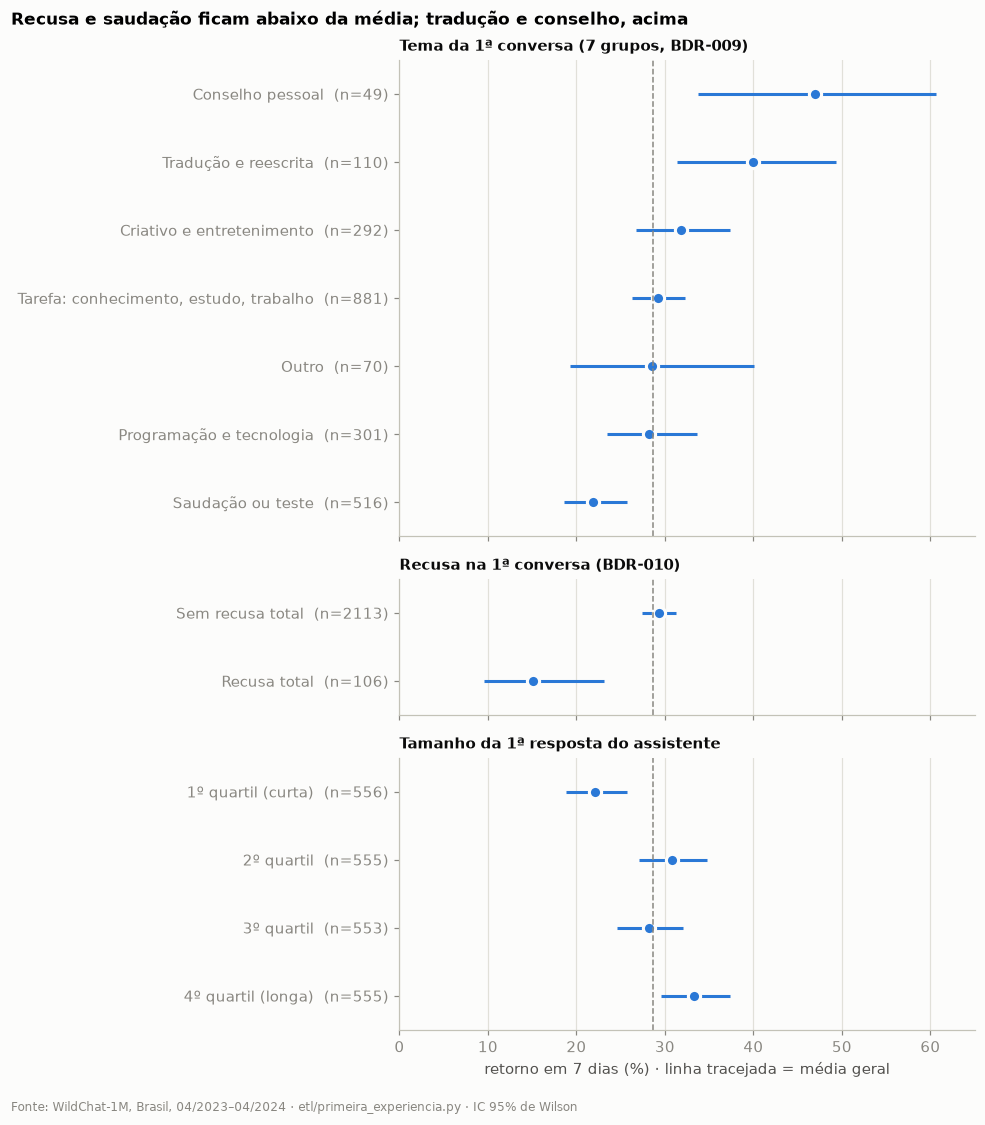

recusa total por tema: {'criativo_entretenimento': 31, 'tarefa_conhecimento': 30, 'programacao_tecnologia': 21, 'outro': 17, 'traducao_reescrita': 4, 'conselho_pessoal': 2, 'saudacao_teste': 1}
saudação no 1º quartil de resposta: 80%


In [4]:
el["resposta_quartil"] = pd.qcut(el.tam_resposta_1, 4, labels=["1º quartil (curta)", "2º quartil", "3º quartil",
                                                                "4º quartil (longa)"])
print("limites dos quartis da 1ª resposta (caracteres):", el.tam_resposta_1.quantile([0.25, 0.5, 0.75]).tolist())
rec = el.assign(rec=el.recusa_total.map({True: "Recusa total", False: "Sem recusa total"}))
painel(
    [
        ("Tema da 1ª conversa (7 grupos, BDR-009)", por_nivel(el, "tema_grupo"), None),
        ("Recusa na 1ª conversa (BDR-010)", por_nivel(rec, "rec", ["Sem recusa total", "Recusa total"]), {}),
        ("Tamanho da 1ª resposta do assistente", por_nivel(el, "resposta_quartil", list(el.resposta_quartil.cat.categories)), {}),
    ],
    "Recusa e saudação ficam abaixo da média; tradução e conselho, acima",
)
print("recusa total por tema:", el[el.recusa_total].tema_grupo.value_counts().to_dict())
print("saudação no 1º quartil de resposta:", f"{(el[el.resposta_quartil.cat.codes == 0].tema_grupo == 'saudacao_teste').mean():.0%}")

**Conclusão:**
- **Recusa total na 1ª conversa: 15% de retorno, contra 29% sem recusa** (−14 p.p., IC sem sobreposição;
  n = 106). É o maior sinal de conteúdo. A recusa quase nunca cai numa saudação (1 de 106): ela atinge pedidos
  reais, de tarefa, criativos e de programação.
- **Saudação ou teste: 22%**, 7 p.p. abaixo da média. Quem só diz "oi" e não pede nada volta menos. Esse grupo é
  o maior depois das tarefas (516 pessoas, 23%).
- **Tradução e conselho pessoal ficam acima** (40% e 47%), mas com IC largo (n = 110 e 49).
- A **resposta curta** (1º quartil, até 119 caracteres) fica em 22%. Em 80% dos casos, ela responde a uma
  saudação. O notebook 04 separa os dois sinais.

## 3. Quem é e quando chega

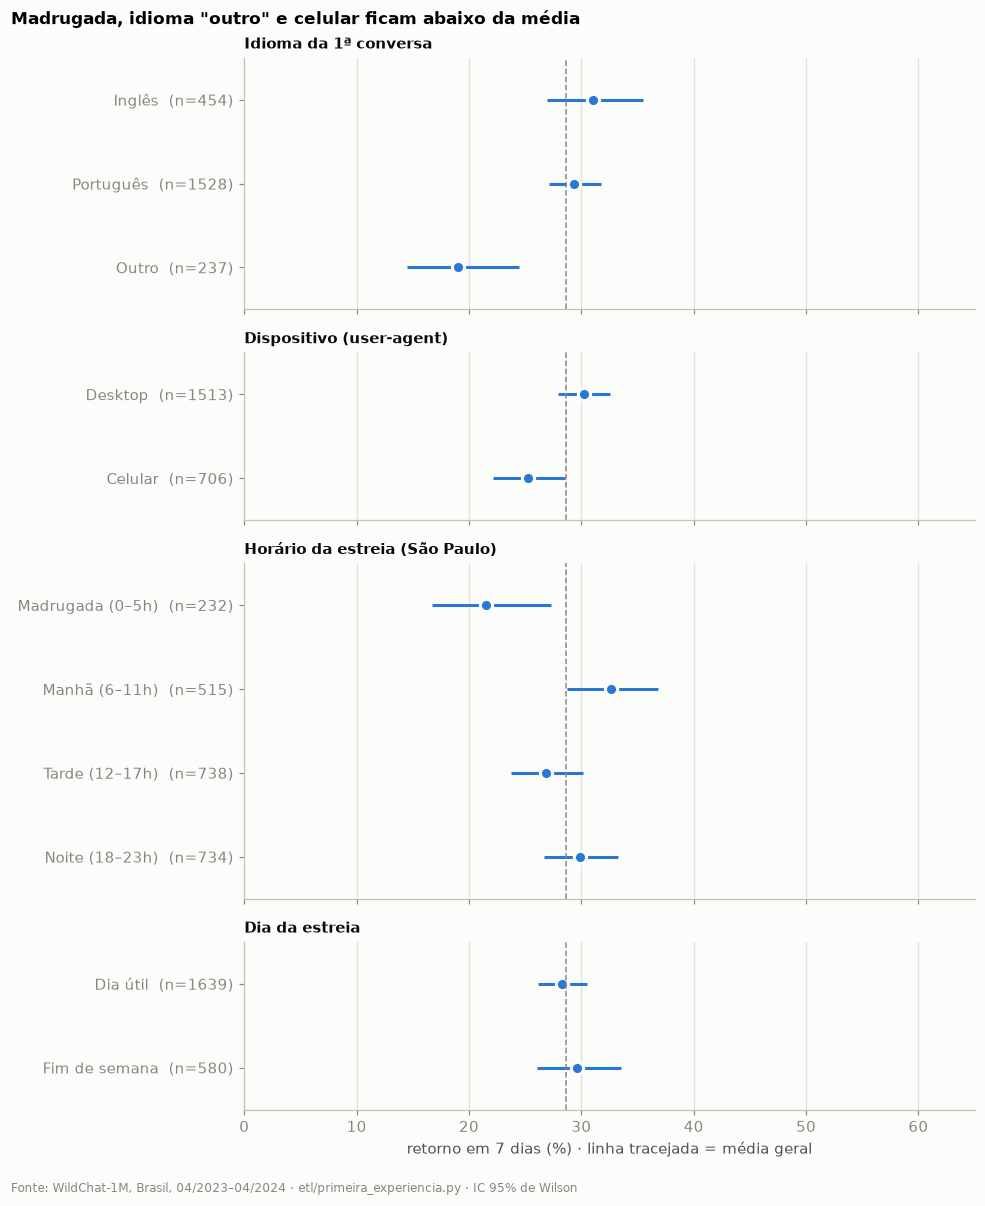

% saudação por idioma: {'ingles': 0.16, 'outro': 0.54, 'portugues': 0.21}


In [5]:
el["semana"] = el.fim_de_semana.map({True: "Fim de semana", False: "Dia útil"})
painel(
    [
        ("Idioma da 1ª conversa", por_nivel(el, "idioma_3"), None),
        ("Dispositivo (user-agent)", por_nivel(el, "dispositivo"), None),
        ("Horário da estreia (São Paulo)", por_nivel(el, "faixa_horaria", ["madrugada", "manha", "tarde", "noite"]), None),
        ("Dia da estreia", por_nivel(el, "semana", ["Dia útil", "Fim de semana"]), {}),
    ],
    "Madrugada, idioma \"outro\" e celular ficam abaixo da média",
)
print("% saudação por idioma:", el.groupby("idioma_3").tema_grupo.apply(lambda s: (s == "saudacao_teste").mean()).round(2).to_dict())

**Conclusão:**
- **Idioma "outro": 19%.** Mais da metade desse grupo (54%) é saudação ou teste: o detector de idioma erra em
  mensagens curtas (notebook 01). O sinal é o da saudação, não o do idioma.
- **Madrugada: 22%**, contra 33% de manhã. **Celular: 25%**, contra 30% no desktop.
- Dia útil e fim de semana não se separam.
- O celular pode carregar um **erro de medição**: a operadora móvel troca o IP, e a pessoa reaparece como
  usuário novo, sem retorno (seção 5).

## 4. Quanto usou na 1ª sessão

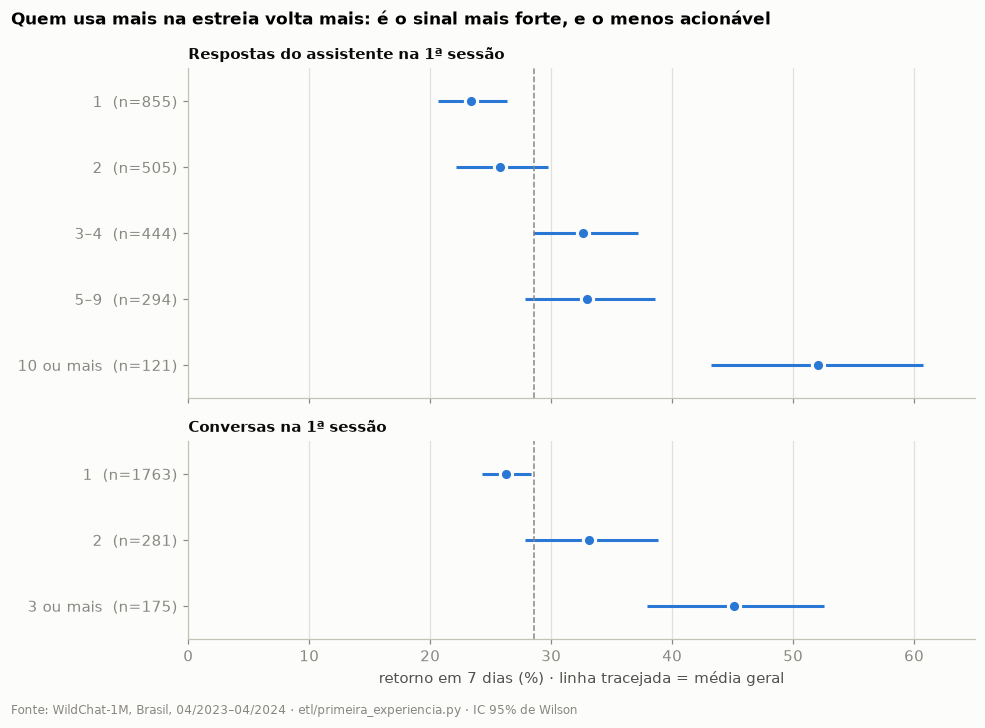

In [6]:
el["respostas"] = pd.cut(el.n_respostas_sessao1, [0, 1, 2, 4, 9, 10**6], labels=["1", "2", "3–4", "5–9", "10 ou mais"])
el["conversas"] = pd.cut(el.n_conversas_sessao1, [0, 1, 2, 10**6], labels=["1", "2", "3 ou mais"])
painel(
    [
        ("Respostas do assistente na 1ª sessão", por_nivel(el, "respostas", list(el.respostas.cat.categories)), {}),
        ("Conversas na 1ª sessão", por_nivel(el, "conversas", list(el.conversas.cat.categories)), {}),
    ],
    "Quem usa mais na estreia volta mais: é o sinal mais forte, e o menos acionável",
)

**Conclusão:**
- **10 ou mais respostas na estreia: 52% de retorno. Uma resposta só: 23%.** É o maior gradiente da base.
- Esse fator é **engajamento**, não alavanca. Ele mistura intenção prévia (quem chega com uma tarefa usa mais) e
  qualidade da experiência (uma recusa encurta a sessão).
- **Decisão para o notebook 04:** o modelo principal fica **sem** o volume da sessão. Assim o efeito da recusa e
  do tema inclui o caminho "experiência ruim → sessão curta → não volta". Um 2º modelo, com o volume, entra como
  sensibilidade.

## 5. Estado: o Rio de Janeiro foge do padrão

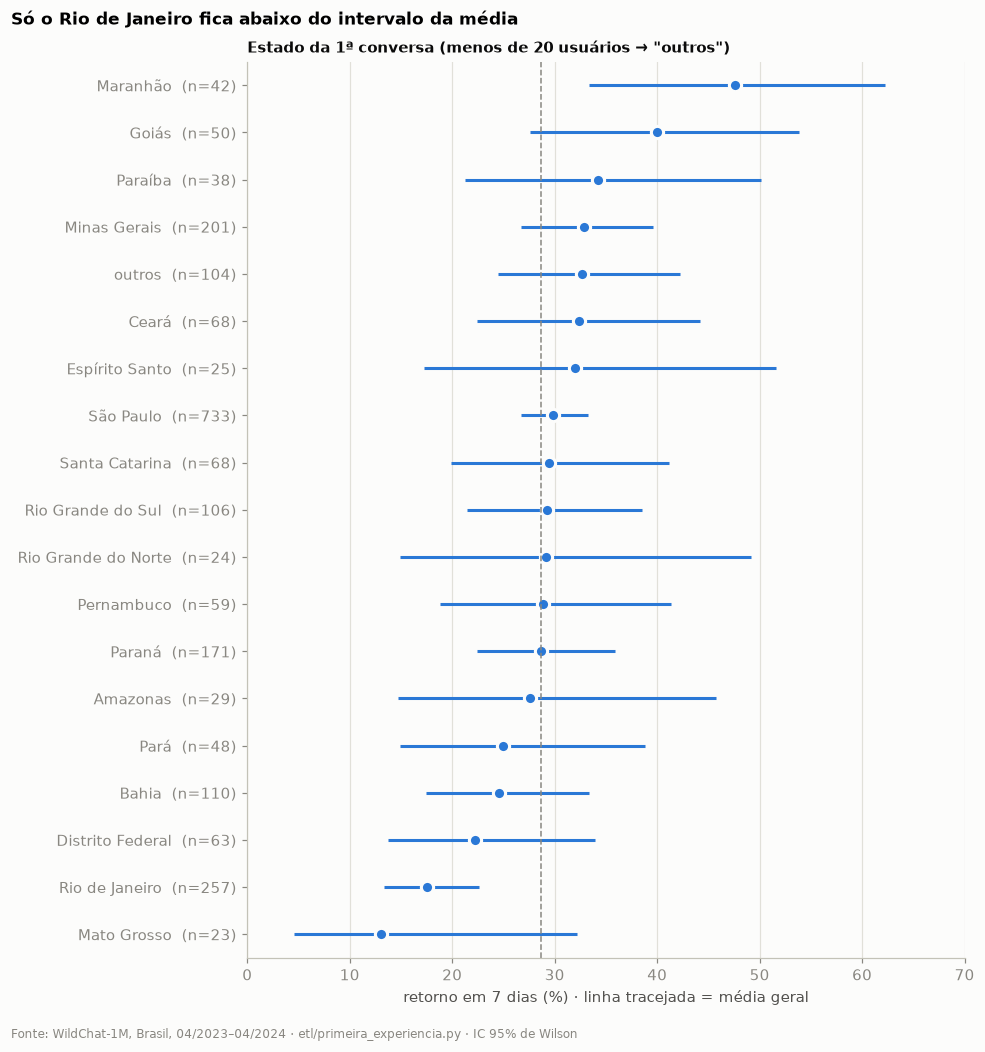

In [7]:
painel([("Estado da 1ª conversa (menos de 20 usuários → \"outros\")", por_nivel(el, "estado_grupo"), {})],
       "Só o Rio de Janeiro fica abaixo do intervalo da média", xmax=70)

In [8]:
# IP dinâmico: o user-agent raro (≤ 3 IPs na base) e o accept-language da 1ª conversa reaparecem em OUTRO IP
# nos 7 dias seguintes. Limite inferior: um user-agent comum não deixa rastro.
outro_ip = con.execute("""
    WITH ua_ips AS (SELECT user_agent, count(DISTINCT hashed_ip) AS n_ips FROM conversas GROUP BY 1),
    prim AS (SELECT usuario_id, first(conversa_id ORDER BY inicio_utc, conversa_id) AS cid
             FROM eventos_sessao WHERE sessao_seq = 1 GROUP BY 1),
    p AS (SELECT prim.usuario_id, pe.primeira_inicio_utc AS t0, c.user_agent, c.accept_language, c.hashed_ip
          FROM prim JOIN primeira_experiencia pe USING (usuario_id) JOIN conversas c ON c.conversa_id = prim.cid)
    SELECT usuario_id,
           user_agent IN (SELECT user_agent FROM ua_ips WHERE n_ips <= 3) AND EXISTS (
               SELECT 1 FROM conversas c
               WHERE c.user_agent = p.user_agent AND c.accept_language = p.accept_language
                 AND c.hashed_ip <> p.hashed_ip
                 AND c.inicio_utc > p.t0 + INTERVAL 30 MINUTE AND c.inicio_utc <= p.t0 + INTERVAL 7 DAY
           ) AS outro_ip_7d
    FROM p
""").df()
x = el.merge(outro_ip, on="usuario_id")
x["regiao"] = x.estado_grupo.eq("Rio de Janeiro").map({True: "Rio de Janeiro", False: "Demais estados"})
t = x.groupby(["regiao", "dispositivo"]).agg(usuarios=("usuario_id", "size"), retorno_7d=("voltou_7d", "mean"),
                                             reaparece_em_outro_ip=("outro_ip_7d", "mean"))
display((t.assign(retorno_7d=t.retorno_7d * 100, reaparece_em_outro_ip=t.reaparece_em_outro_ip * 100)).round(1))
print("celular no Rio:", f"{(el[el.estado_grupo == 'Rio de Janeiro'].dispositivo == 'mobile').mean():.0%}",
      "| no resto:", f"{(el[el.estado_grupo != 'Rio de Janeiro'].dispositivo == 'mobile').mean():.0%}")

usuarios  retorno_7d  reaparece_em_outro_ip
regiao         dispositivo                                             
Demais estados desktop          1398        31.1                    0.8
               mobile            564        27.5                    2.5
Rio de Janeiro desktop           115        19.1                    2.6
               mobile            142        16.2                    5.6

celular no Rio: 55% | no resto: 29%


**Conclusão:**
- **Rio de Janeiro: 17,5% de retorno (n = 257), 11 p.p. abaixo da média.** O IC (13–23%) não toca a média.
  O Maranhão fica acima (48%, n = 42). Com 19 estados, um desvio desses pode ser acaso.
- **O Rio fica baixo nos dois dispositivos** (19% no desktop, 16% no celular). O mix de celular (55% no Rio,
  29% no resto) não explica a diferença.
- **No Rio, o user-agent raro reaparece em outro IP 2 a 3× mais** (2,6% e 5,6%, contra 0,8% e 2,5%). Isso é um
  limite inferior de IP dinâmico. **Hipótese:** parte da queda do Rio é **medição**, não comportamento. A
  operadora troca o IP, e a mesma pessoa vira um "novo" usuário que nunca volta (BDR-001, risco 1).
- **Decisão:** o estado entra no notebook 04 como **controle**, não como achado. O caso do Rio vai para o
  `RISCOS.md` como evidência do limite da definição de usuário por IP.

## 6. Modelo: confundido com o tempo

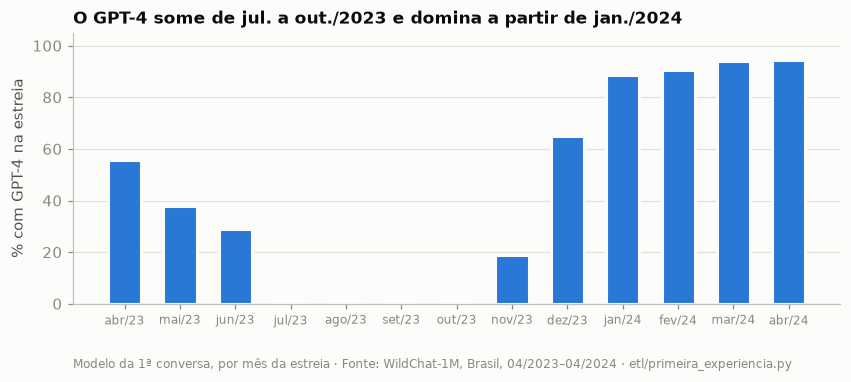

meses com os dois modelos (10–90% de GPT-4): ['04/2023', '05/2023', '06/2023', '11/2023', '12/2023', '01/2024']
base inteira {'gpt-3.5': '28.4% (IC 25.9%–30.9%, n=1241)', 'gpt-4': '28.9% (IC 26.2%–31.9%, n=978)'}
só meses com os dois {'gpt-3.5': '28.1% (IC 24.8%–31.7%, n=644)', 'gpt-4': '30.1% (IC 25.9%–34.6%, n=429)'}


In [9]:
m = el.groupby("coorte_mes").agg(usuarios=("usuario_id", "size"),
                                 gpt4=("familia_modelo", lambda s: (s == "gpt-4").mean()))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(len(m)), m.gpt4 * 100, color=AZUL, width=0.6, edgecolor=FUNDO, linewidth=2)
MESES = "jan fev mar abr mai jun jul ago set out nov dez".split()
ax.set_xticks(range(len(m)), [f"{MESES[d.month - 1]}/{d:%y}" for d in m.index], fontsize=8)
ax.set_ylabel("% com GPT-4 na estreia")
ax.set_ylim(0, 105)
ax.set_title("O GPT-4 some de jul. a out./2023 e domina a partir de jan./2024")
ax.annotate("Modelo da 1ª conversa, por mês da estreia · " + FONTE_BASE, xy=(0, -0.2), xycoords="axes fraction",
            fontsize=8, color=TINTA_MUDA, va="top")
plt.show()

mistos = m[(m.gpt4 > 0.1) & (m.gpt4 < 0.9)].index
print("meses com os dois modelos (10–90% de GPT-4):", [d.strftime("%m/%Y") for d in mistos])
for nome, df in [("base inteira", el), ("só meses com os dois", el[el.coorte_mes.isin(mistos)])]:
    g = por_nivel(df, "familia_modelo", ["gpt-3.5", "gpt-4"])
    print(nome, {i: f"{r.taxa:.1%} (IC {r.lo:.1%}–{r.hi:.1%}, n={int(r.n)})" for i, r in g.iterrows()})

**Conclusão:**
- **Sem ajuste, o modelo não separa quem volta:** 28% (GPT-3.5) e 29% (GPT-4) na base inteira.
- A comparação bruta é **injusta**: o modelo muda com o mês, e o mês muda o perfil de quem chega (lançamento,
  férias). Nos 6 meses com os dois modelos, o GPT-4 fica 2 p.p. acima, com IC sobreposto.
- **Decisão para o notebook 04:** comparar modelos **dentro do mesmo mês**, com o mês como controle do ajuste.

## 7. O que vai para o notebook 04

| Fator | Sinal bruto, contra a média de 28,6% | Como entra no modelo |
|---|---|---|
| Recusa total na 1ª conversa | −14 p.p. | Fator principal (BDR-010); regex e sessão inteira como sensibilidade |
| Tema (7 grupos) | saudação −7 p.p.; tradução e conselho acima | Fator (BDR-009); referência = tarefa |
| Horário | madrugada −7 p.p. | Fator, 4 faixas |
| Dispositivo | celular −3 p.p. (−5 contra o desktop) | Fator, com a ressalva de medição (seção 5) |
| Idioma | "outro" −10 p.p. | Fator, 3 níveis; compete com a saudação |
| Tamanho da 1ª resposta | 1º quartil −6 p.p. | Fator em quartis; compete com a saudação |
| Modelo | ≈ 0 bruto | Fator; o mês como controle faz a comparação dentro do mesmo mês |
| Estado | Rio −11 p.p. | Controle, não achado |
| Mês da estreia | abr/2023 e jan/2024 fora do padrão | Controle; seção do mês atípico |
| Volume da 1ª sessão | +23 p.p. com 10 ou mais respostas | **Fora** do modelo principal (engajamento); entra na sensibilidade |
| Dia útil × fim de semana | ≈ 0 | Fora |
| `redacted` | n = 13 | Fora: amostra pequena |